# Task 03: Feature Engineering & Preprocessing Pipeline
### Predicting California house prices with a leak-free scikit-learn pipeline

**Author:** Aathika Begam A

Raw data is almost never ready for a model. It has gaps, numbers on wildly different scales, and text columns that a model can't read. The goal of this task is to build **one reusable pipeline** that takes the raw table and turns it into clean model input, without letting any information from the test set sneak into training.

Here's what I'm going to do, in order:

1. Load the California Housing Prices dataset
2. **Split into train and test first**, before touching anything else
3. Explore the training data (missing values, skew, correlations)
4. Build a `ColumnTransformer` that handles each column type properly
5. Check that nothing leaked
6. Rank the features with mutual information, a random forest, and permutation importance
7. Wrap everything into a single pipeline I can reuse

## 1. Setup

In [1]:
import io
import tarfile
import urllib.request
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    StandardScaler,
    TargetEncoder,
)

RANDOM_STATE = 42

# Newer scikit-learn versions (1.9+) print a deprecation notice about TargetEncoder's
# random_state argument. It's harmless and just clutters the output, so I hide it.
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn.preprocessing._target_encoder")

import sklearn
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

# Plot styling: light grid, no chart junk, one blue for single-measure charts
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
DIVERGING = LinearSegmentedColormap.from_list("blue_orange", [BLUE, "#f4f3f0", ORANGE])
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c3",
    "axes.grid": True,
    "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
})

scikit-learn 1.9.1 | pandas 3.0.5


## 2. Load the data

I'm using the California Housing Prices dataset (from the 1990 census). Each row is a **block group**, a small neighbourhood-sized area, and the job is to predict `median_house_value`, so this is a regression problem.

I picked it because it has the messy bits the task asks for: missing values, a text column, features with very different scales, and some heavily skewed counts. The cell below reads a local `housing.csv` if one is sitting next to the notebook, otherwise it downloads the file from GitHub.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.tgz"
LOCAL_CSV = Path("housing.csv")


def load_housing() -> pd.DataFrame:
    if LOCAL_CSV.exists():
        return pd.read_csv(LOCAL_CSV)
    with urllib.request.urlopen(DATA_URL) as resp:
        raw = resp.read()
    with tarfile.open(fileobj=io.BytesIO(raw), mode="r:gz") as tar:
        return pd.read_csv(tar.extractfile("housing.csv"))


df = load_housing()
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

20,640 rows x 10 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


A quick look at the column types before I do anything else. Only `ocean_proximity` is text. Everything else is numeric.

In [3]:
df.dtypes.to_frame("dtype").T

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,str


## 3. Train/test split (before anything else)

This is the most important step in the whole notebook. I split the data **now**, before I compute a single mean, median or category list. From here on the test set is locked away: I never fit anything on it. I only use it for *evaluation* (the leak checks, permutation importance and the final scores), where it plays the role of data the pipeline has never seen.

One extra detail: median income is the strongest driver of house prices here, so I want train and test to have the same mix of rich and poor areas. I use `stratify` on income bands for that. The bands are only used to decide *which rows go where*. They never become a feature.

In [4]:
TARGET = "median_house_value"

X = df.drop(columns=TARGET)
y = df[TARGET]

income_band = pd.cut(
    df["median_income"], bins=[0, 1.5, 3, 4.5, 6, np.inf], labels=[1, 2, 3, 4, 5]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=income_band
)

print(f"Train: {X_train.shape[0]:,} rows | Test: {X_test.shape[0]:,} rows")

# Sanity check: the income mix should look nearly identical in both halves
pd.DataFrame({
    "train": income_band.loc[X_train.index].value_counts(normalize=True).sort_index(),
    "test": income_band.loc[X_test.index].value_counts(normalize=True).sort_index(),
}).round(3)

Train: 16,512 rows | Test: 4,128 rows


,train,test
median_income,,
1,0.040,0.040
2,0.319,0.319
3,0.351,0.351
4,0.176,0.176
5,0.114,0.114


## 4. Feature engineering helper

The raw counts (`total_rooms`, `population`, ...) depend on how big a block group is, which makes them hard to compare. Ratios are usually more meaningful, so I add three:

- `rooms_per_household`
- `bedrooms_per_room`
- `people_per_household`

I also turn latitude and longitude into a coarse **location cell**, a half-degree grid square (roughly 50 km wide). That gives me a text-like column with lots of unique values, which is exactly the situation where one-hot encoding gets clumsy and **target encoding** makes more sense.

Does building these before fitting cause leakage? No, because each new value only uses numbers from its *own row*. Nothing is learned from other rows, so nothing can leak. I'll still put the function inside the pipeline later so the whole thing stays in one object.

In [5]:
def add_features(data: pd.DataFrame) -> pd.DataFrame:
    """Row-wise feature engineering. Uses only each row's own values, so it can't leak."""
    data = data.copy()
    data["rooms_per_household"] = data["total_rooms"] / data["households"]
    data["bedrooms_per_room"] = data["total_bedrooms"] / data["total_rooms"]
    data["people_per_household"] = data["population"] / data["households"]
    lat_cell = (data["latitude"] / 0.5).round().astype(int).astype(str)
    lon_cell = (data["longitude"] / 0.5).round().astype(int).astype(str)
    data["geo_cell"] = lat_cell + "_" + lon_cell
    return data


train_eda = add_features(X_train)
print(f"geo_cell has {train_eda['geo_cell'].nunique()} unique values in the training set")
train_eda[["rooms_per_household", "bedrooms_per_room", "people_per_household", "geo_cell"]].head()

geo_cell has 183 unique values in the training set


,rooms_per_household,bedrooms_per_room,people_per_household,geo_cell
12655,5.485836,0.205784,3.168555,77_-243
15502,6.927083,0.160714,2.623698,66_-234
2908,5.393333,0.191595,2.223333,71_-238
14053,3.886128,0.276505,1.859213,66_-234
20496,6.096552,0.182692,3.167241,69_-237


## 5. Exploring the training data

Everything from here to the pipeline uses the **training set only**. If I let the test set influence my decisions here, even just by looking at it, I'd be leaking a little bit of it into my choices.

### 5.1 Missing values

In [6]:
missing = train_eda.isna().sum()
missing = missing[missing > 0].to_frame("missing_count")
missing["percent"] = (missing["missing_count"] / len(train_eda) * 100).round(2)
missing

,missing_count,percent
total_bedrooms,158,0.96
bedrooms_per_room,158,0.96


`total_bedrooms` is the only raw column with gaps, and `bedrooms_per_room` inherits those gaps because it's built from it. The pipeline will fill them using the **median of the training set**.

### 5.2 The target and the skew in the count columns

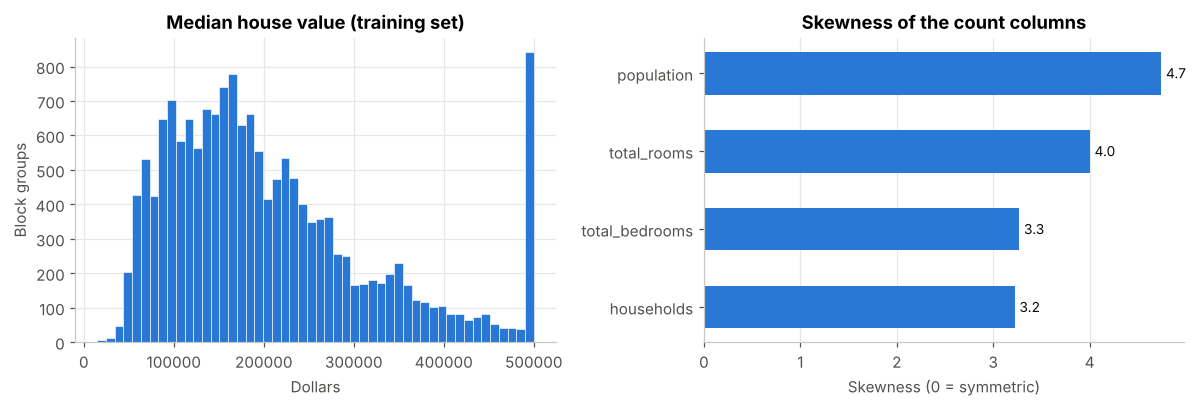

Block groups at the $500,001 price cap: 809


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].hist(y_train, bins=50, color=BLUE, edgecolor="white", linewidth=0.4)
axes[0].set_title("Median house value (training set)")
axes[0].set_xlabel("Dollars")
axes[0].set_ylabel("Block groups")

skew = train_eda[["total_rooms", "total_bedrooms", "population", "households"]].skew().sort_values()
axes[1].barh(skew.index, skew.values, color=BLUE, height=0.55)
axes[1].set_title("Skewness of the count columns")
axes[1].set_xlabel("Skewness (0 = symmetric)")
for i, v in enumerate(skew.values):
    axes[1].text(v + 0.05, i, f"{v:.1f}", va="center", color=INK, fontsize=9)
axes[1].grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

print("Block groups at the $500,001 price cap:", int((y_train >= 500_000).sum()))

Two things stand out:

- The house value histogram has a tall spike at the far right. The original survey **capped** prices at about $500,000, so every expensive area got squashed into the same value. That's a property of the data, and it's worth remembering when reading model errors later.
- The count columns are very right-skewed, with a few huge block groups dragging the tail out. A plain `StandardScaler` would be thrown off by those, so I'll apply a **log transform** before scaling for these four columns.

### 5.3 Correlation analysis

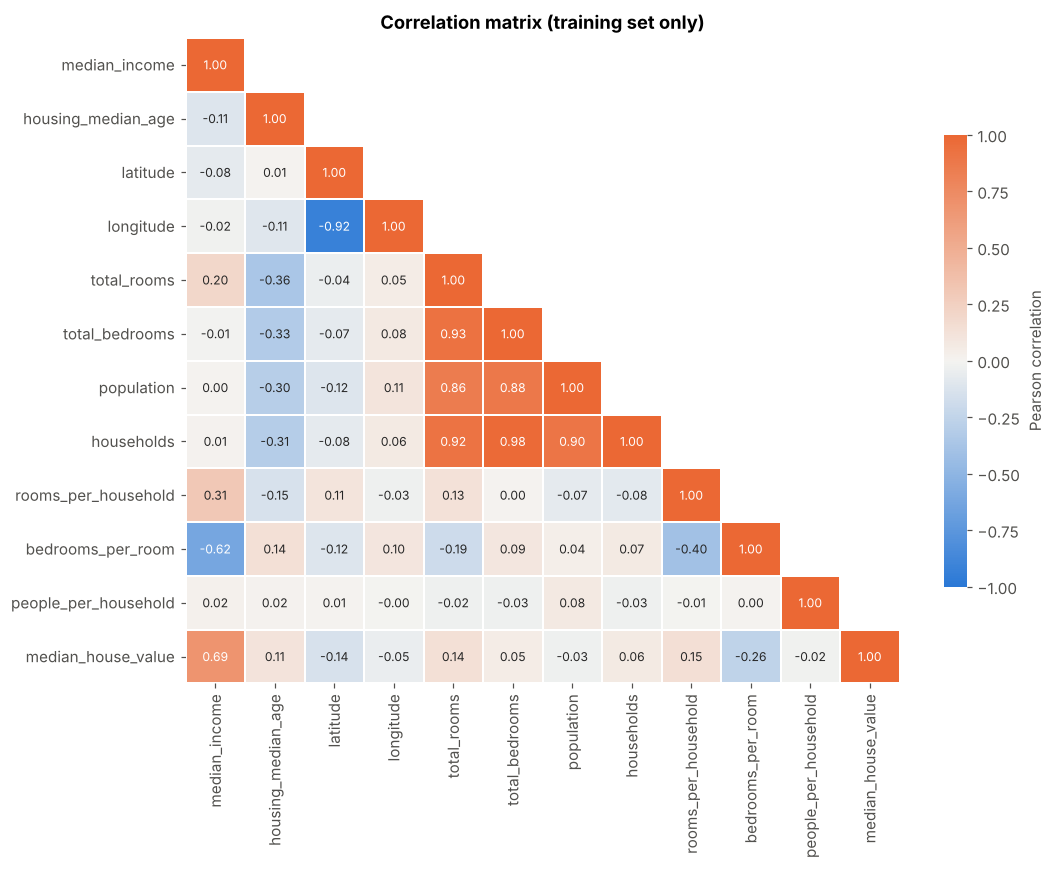

In [8]:
corr_cols = [
    "median_income", "housing_median_age", "latitude", "longitude",
    "total_rooms", "total_bedrooms", "population", "households",
    "rooms_per_household", "bedrooms_per_room", "people_per_household",
]
corr_df = train_eda[corr_cols].assign(**{TARGET: y_train})
corr = corr_df.corr()

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr, mask=mask, cmap=DIVERGING, center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=1, linecolor="white",
    cbar_kws={"shrink": 0.7, "label": "Pearson correlation"}, ax=ax,
)
ax.set_title("Correlation matrix (training set only)")
ax.grid(False)
plt.tight_layout()
plt.show()

In [9]:
# Which features move with the target the most?
target_corr = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print("Correlation with median_house_value:\n")
print(target_corr.round(3).to_string())

# Which feature pairs are so correlated they're basically duplicates?
upper = corr.drop(index=TARGET, columns=TARGET)
upper = upper.where(np.triu(np.ones(upper.shape, dtype=bool), k=1))
strong = upper.stack().loc[lambda s: s.abs() > 0.8].sort_values(key=abs, ascending=False)
print("\nPairs with |correlation| above 0.8:\n")
print(strong.round(3).to_string())

Correlation with median_house_value:

median_income           0.687
bedrooms_per_room      -0.260
rooms_per_household     0.146
latitude               -0.143
total_rooms             0.135
housing_median_age      0.114
households              0.065
total_bedrooms          0.048
longitude              -0.047
population             -0.027
people_per_household   -0.022

Pairs with |correlation| above 0.8:

total_bedrooms  households        0.980
total_rooms     total_bedrooms    0.929
latitude        longitude        -0.924
total_rooms     households        0.918
population      households        0.905
total_bedrooms  population        0.876
total_rooms     population        0.855


**What the correlations tell me**

- **Median income is the clear leader**, with a correlation of about 0.69 with house value. Nothing else comes close. The next strongest is `bedrooms_per_room` at about -0.26. I'd be careful reading much into that one, because it also correlates at -0.62 with income, so a good part of it is probably just income showing up a second time.
- **The four raw count columns are nearly the same feature.** `total_bedrooms` and `households` correlate at 0.98, and every pair among `total_rooms`, `total_bedrooms`, `population` and `households` is above 0.85. They mostly just measure "how big is this block group". That's harmless for tree models, but a linear model would struggle with this much overlap (multicollinearity). It's also a good reason why the ratio features I built are more useful than the raw counts.
- **Latitude and longitude are tied together** (-0.92) because California's coastline runs diagonally. That's one more reason to combine them into a location cell instead of treating them as two independent numbers.
- Correlation only captures *straight-line* relationships. A feature can look useless here and still matter. That's why I add mutual information and tree-based rankings below.

## 6. Building the preprocessing pipeline

Different column types need different treatment, so I group them and give each group its own mini-pipeline:

| Group | Columns | Steps |
|---|---|---|
| Numeric | longitude, latitude, housing_median_age, median_income, the three ratios | median imputation → standard scaling |
| Skewed counts | total_rooms, total_bedrooms, population, households | median imputation → `log1p` → standard scaling |
| Low-cardinality category | ocean_proximity (5 values) | most-frequent imputation → one-hot encoding |
| High-cardinality category | geo_cell (~190 values) | most-frequent imputation → target encoding |

A few choices worth explaining:

- **Median, not mean, for imputing.** The medians are robust to the extreme values we saw above.
- **One-hot for `ocean_proximity`.** Only five categories, so five little columns is fine. `handle_unknown="ignore"` means a category that never appeared in training won't crash the pipeline later.
- **Target encoding for `geo_cell`.** One-hot would create ~190 mostly empty columns. Target encoding replaces each cell with a smoothed average of the house value in that cell. The scikit-learn `TargetEncoder` uses **cross-fitting** during `fit_transform`: each training row is encoded using statistics from the *other* folds, so a row never sees its own target. That's what stops target encoding from leaking the answer.

In [10]:
NUMERIC_COLS = [
    "longitude", "latitude", "housing_median_age", "median_income",
    "rooms_per_household", "bedrooms_per_room", "people_per_household",
]
SKEWED_COLS = ["total_rooms", "total_bedrooms", "population", "households"]
ONEHOT_COLS = ["ocean_proximity"]
TARGET_ENC_COLS = ["geo_cell"]


def build_preprocessor() -> ColumnTransformer:
    numeric_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    skewed_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    onehot_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    target_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", TargetEncoder(target_type="continuous", smooth="auto", random_state=RANDOM_STATE)),
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipe, NUMERIC_COLS),
            ("skewed", skewed_pipe, SKEWED_COLS),
            ("onehot", onehot_pipe, ONEHOT_COLS),
            ("target_enc", target_pipe, TARGET_ENC_COLS),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    preprocessor.set_output(transform="pandas")
    return preprocessor


def build_feature_pipeline() -> Pipeline:
    """Raw table in -> model-ready table out."""
    return Pipeline([
        ("add_features", FunctionTransformer(add_features)),
        ("preprocess", build_preprocessor()),
    ])


feature_pipeline = build_feature_pipeline()
feature_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('add_features', ...), ('preprocess', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...x7f9e9ce00860>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictio

### Fit on train, transform on test

This is the leak-free part in practice. `fit_transform` runs on the training data only, so every median, mean, standard deviation and category list is learned from there. The test set only goes through `transform`, which just *applies* what was already learned.

In [11]:
X_train_prep = feature_pipeline.fit_transform(X_train, y_train)   # learns from train
X_test_prep = feature_pipeline.transform(X_test)                   # only applies

print("Train matrix:", X_train_prep.shape)
print("Test matrix: ", X_test_prep.shape)
X_train_prep.head()

Train matrix: (16512, 17)
Test matrix:  (4128, 17)


,longitude,latitude,housing_median_age,median_income,rooms_per_household,bedrooms_per_room,people_per_household,total_rooms,total_bedrooms,population,households,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN,geo_cell
12655,-0.941350,1.347438,0.027564,-0.893647,0.017395,-0.122484,0.006223,0.852802,0.876814,0.939807,0.800912,0.0,1.0,0.0,0.0,0.0,125882.255722
15502,1.171782,-1.192440,-1.722018,1.292168,0.569256,-0.911663,-0.040811,1.278834,0.974434,0.797735,0.917052,0.0,0.0,0.0,0.0,1.0,199884.985331
2908,0.267581,-0.125972,1.220460,-0.525434,-0.018024,-0.370939,-0.075371,-0.318385,-0.434286,-0.704456,-0.378893,0.0,1.0,0.0,0.0,0.0,80362.682582
14053,1.221738,-1.351474,-0.370069,-0.865929,-0.595140,1.115873,-0.106803,-0.119179,0.280923,-0.300554,0.277348,0.0,0.0,0.0,0.0,1.0,202282.295545
20496,0.437431,-0.635818,-0.131489,0.325752,0.251241,-0.526821,0.006109,0.730635,0.584959,0.672024,0.529725,1.0,0.0,0.0,0.0,0.0,232973.507634


## 7. Checking that nothing leaked

I don't want to just claim the pipeline is leak-free, so here are four quick checks.

In [12]:
# Check 1: no missing values left, and train/test have identical columns
assert X_train_prep.isna().sum().sum() == 0, "NaNs left in train"
assert X_test_prep.isna().sum().sum() == 0, "NaNs left in test"
assert list(X_train_prep.columns) == list(X_test_prep.columns), "Column mismatch"
print("Check 1 passed: no NaNs, and train/test columns match")

# Check 2: the imputer's medians came from the TRAINING data, not the full dataset
prep = feature_pipeline.named_steps["preprocess"]
imputer = prep.named_transformers_["numeric"].named_steps["impute"]
train_medians = add_features(X_train)[NUMERIC_COLS].median()
full_medians = add_features(X)[NUMERIC_COLS].median()
assert np.allclose(imputer.statistics_, train_medians.values)
print("Check 2 passed: imputer medians equal the training medians")

pd.DataFrame({
    "used by pipeline": imputer.statistics_,
    "train median": train_medians.values,
    "full-data median": full_medians.values,
}, index=NUMERIC_COLS).round(4)

Check 1 passed: no NaNs, and train/test columns match
Check 2 passed: imputer medians equal the training medians


,used by pipeline,train median,full-data median
longitude,-118.5100,-118.5100,-118.4900
latitude,34.2600,34.2600,34.2600
housing_median_age,29.0000,29.0000,29.0000
median_income,3.5416,3.5416,3.5348
rooms_per_household,5.2323,5.2323,5.2291
bedrooms_per_room,0.2030,0.2030,0.2032
people_per_household,2.8177,2.8177,2.8181


In [13]:
# Check 3: scaler means match the training data
scaler = prep.named_transformers_["numeric"].named_steps["scale"]
assert np.allclose(scaler.mean_, add_features(X_train)[NUMERIC_COLS].fillna(train_medians).mean().values)
print("Check 3 passed: scaler mean_ values were learned from the training data")

# Check 4: scaled train columns average exactly 0; scaled test columns do NOT
# (if the test set had been used to fit the scaler, both would be ~0)
compare = pd.DataFrame({
    "train mean (scaled)": X_train_prep[NUMERIC_COLS].mean(),
    "test mean (scaled)": X_test_prep[NUMERIC_COLS].mean(),
})
compare.round(4)

Check 3 passed: scaler mean_ values were learned from the training data


,train mean (scaled),test mean (scaled)
longitude,0.0,0.0148
latitude,0.0,-0.0174
housing_median_age,0.0,-0.0055
median_income,-0.0,-0.0137
rooms_per_household,-0.0,-0.0218
bedrooms_per_room,0.0,0.0140
people_per_household,0.0,-0.0111


The table above also shows why this matters. The medians from the full dataset differ slightly from the training medians (for example `median_income` is 3.5348 vs 3.5416). The differences are small, but they're real: if I had imputed before splitting, a tiny bit of the test set would have leaked into every filled-in value.

For the last check, the scaled train columns average to exactly zero (which a fitted `StandardScaler` guarantees), while the test columns land *close to* zero but not on it, within about 0.02. That small gap is the proof I wanted: the scaler never saw the test data, so to it the test set looks like genuinely new data.

One more place leakage likes to hide is **target encoding**, because the encoded value is built from the answer. That's why I used scikit-learn's `TargetEncoder`, which encodes each training row using only the *other* folds. A hand-rolled `groupby().mean()` on the training set would let every row see its own price.

## 8. Feature importance

Now for the "which features actually matter" part. I'm using three different lenses because each one has blind spots:

1. **Mutual information.** Measures how much knowing a feature reduces uncertainty about the price. It catches non-linear relationships that correlation misses.
2. **Random forest importance.** How much each feature helps the trees make splits. Fast, but it can favour continuous features with many unique values.
3. **Permutation importance (on the test set).** Shuffle one feature and see how much the model's score drops. It's the most honest of the three because it's measured on unseen data.

MI and the forest importances are computed on the training set only.

In [14]:
# Lens 1: mutual information
mi = mutual_info_regression(X_train_prep, y_train, random_state=RANDOM_STATE)
mi_scores = pd.Series(mi, index=X_train_prep.columns).sort_values(ascending=False)

# Lens 2: random forest importances
rf = RandomForestRegressor(
    n_estimators=150, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
)
rf.fit(X_train_prep, y_train)
rf_scores = pd.Series(rf.feature_importances_, index=X_train_prep.columns).sort_values(ascending=False)

# Lens 3: permutation importance on the held-out test set
perm = permutation_importance(
    rf, X_test_prep, y_test, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)
perm_scores = pd.Series(perm.importances_mean, index=X_test_prep.columns).sort_values(ascending=False)

importance = pd.DataFrame({
    "mutual_info": mi_scores,
    "rf_importance": rf_scores,
    "permutation": perm_scores,
}).sort_values("rf_importance", ascending=False)
importance.round(4)

,mutual_info,rf_importance,permutation
median_income,0.3852,0.4531,0.5373
geo_cell,0.3980,0.2435,0.3995
people_per_household,0.0634,0.1099,0.1653
latitude,0.3656,0.0384,0.0770
housing_median_age,0.0361,0.0375,0.0483
longitude,0.3978,0.0308,0.0521
rooms_per_household,0.1004,0.0242,0.0195
bedrooms_per_room,0.1427,0.0199,0.0181
total_rooms,0.0329,0.0102,0.0006
population,0.0206,0.0093,0.0003


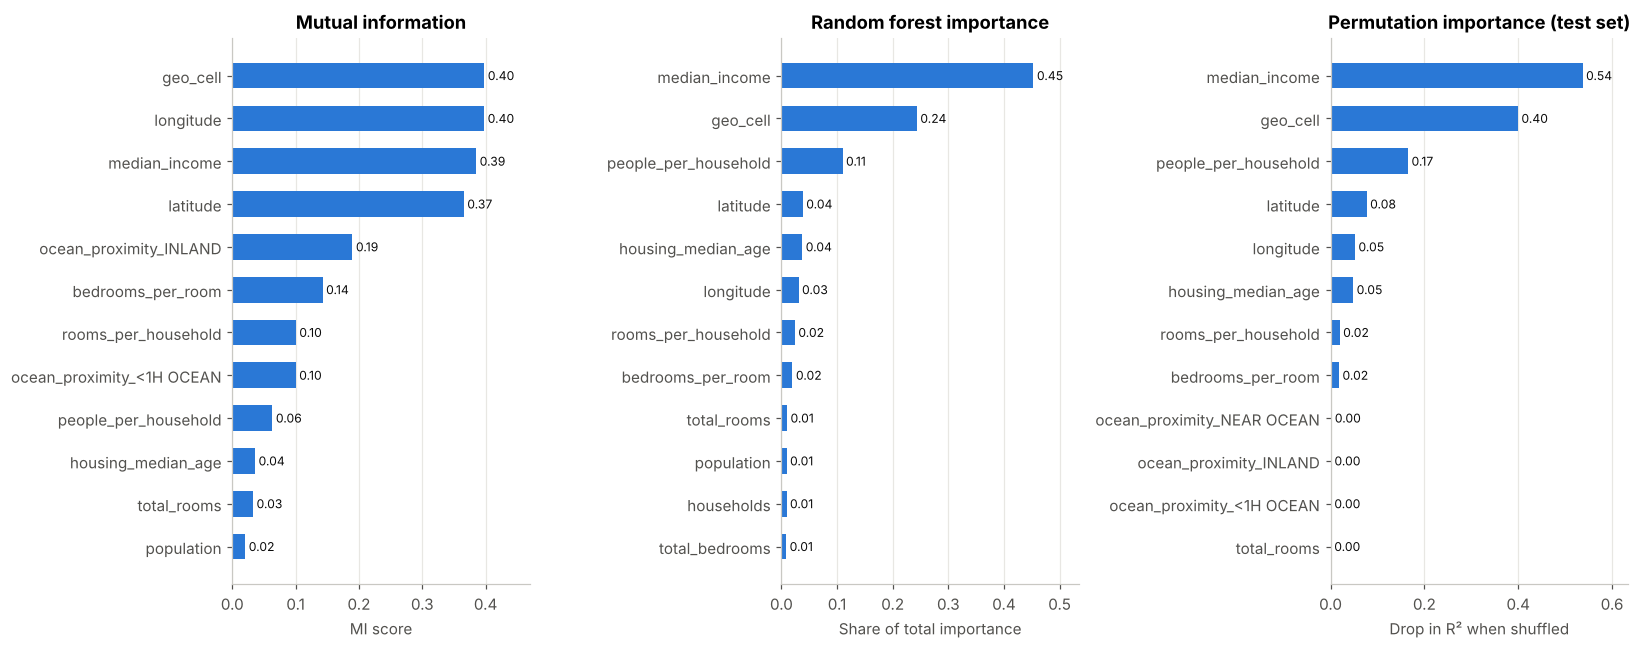

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=False)
panels = [
    (mi_scores, "Mutual information", "MI score"),
    (rf_scores, "Random forest importance", "Share of total importance"),
    (perm_scores, "Permutation importance (test set)", "Drop in R² when shuffled"),
]
for ax, (scores, title, xlabel) in zip(axes, panels):
    top = scores.head(12).iloc[::-1]
    ax.barh(top.index, top.values, color=BLUE, height=0.6)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    for i, v in enumerate(top.values):
        ax.text(v, i, f" {v:.2f}", va="center", color=INK, fontsize=8)
    ax.set_xlim(0, top.max() * 1.18)
plt.tight_layout()
plt.show()

In [16]:
# Do the three lenses agree? Compare their rankings.
ranks = importance.rank(ascending=False).astype(int)
ranks["avg_rank"] = ranks.mean(axis=1).round(1)
ranks.sort_values("avg_rank")

,mutual_info,rf_importance,permutation,avg_rank
median_income,3,1,1,1.7
geo_cell,1,2,2,1.7
latitude,4,4,4,4.0
longitude,2,6,5,4.3
people_per_household,9,3,3,5.0
housing_median_age,10,5,6,7.0
rooms_per_household,7,7,7,7.0
bedrooms_per_room,6,8,8,7.3
ocean_proximity_INLAND,5,14,10,9.7
total_rooms,11,9,12,10.7


**What the rankings tell me**

- **Two features lead.** `median_income` and the engineered `geo_cell` take the top two spots in both the forest and permutation rankings, and they tie for the best average rank across all three methods. In the mutual information chart they're in the top three too (alongside `longitude`, which is really just part of what `geo_cell` encodes). That's a nice result for the feature engineering: the location cell I built, which doesn't exist in the raw data, turned out to be one of the most useful columns. And because the permutation score is measured on the test set, I can trust it isn't just the target encoding memorising the training data.
- **The location features overlap.** Mutual information ranks `longitude`, `latitude` and `ocean_proximity_INLAND` high, but the forest and permutation importance rank them much lower. My explanation is redundancy: once the model has `geo_cell`, those columns add little new. MI scores each feature on its own and doesn't see that overlap, while permutation importance does.
- **`people_per_household` was a surprise.** It has almost no linear correlation with price (-0.02) and a low MI score, yet the forest ranks it third. So its effect seems to be non-linear or to work in combination with other features. I haven't dug into exactly why, so I'd treat it as something to investigate rather than a conclusion.
- **The raw count columns barely matter** (`total_rooms`, `population`, `households`, `total_bedrooms` all have permutation importance near zero). They're almost copies of each other, and the ratio features already carry what's useful from them. If I wanted a leaner model, these are the first candidates to drop.

A caution on the random forest's own importance numbers: they can favour continuous features with many unique values, which is why I wouldn't rely on that one alone.

## 9. The reusable pipeline

So far I've been running the steps one at a time so I could inspect them. The last piece is to chain the feature pipeline and a model into a single object. Because the preprocessing lives *inside* the pipeline, cross-validation re-learns every median, scale and encoding from each training fold separately. That means even the CV scores are leak-free.

In [17]:
def build_full_pipeline() -> Pipeline:
    return Pipeline([
        ("add_features", FunctionTransformer(add_features)),
        ("preprocess", build_preprocessor()),
        ("model", RandomForestRegressor(
            n_estimators=150, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
        )),
    ])


full_pipeline = build_full_pipeline()

cv_scores = cross_val_score(full_pipeline, X_train, y_train, cv=5, scoring="r2")
print(f"5-fold CV R² on train: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")

full_pipeline.fit(X_train, y_train)
test_pred = full_pipeline.predict(X_test)
print(f"Test R²:  {r2_score(y_test, test_pred):.3f}")
print(f"Test MAE: ${mean_absolute_error(y_test, test_pred):,.0f}")

5-fold CV R² on train: 0.821 (+/- 0.006)


Test R²:  0.836
Test MAE: $30,482


In [18]:
# Save the fitted pipeline so it can be reloaded and used on brand-new raw data
joblib.dump(full_pipeline, "housing_pipeline.joblib", compress=3)   # compress keeps the file small
reloaded = joblib.load("housing_pipeline.joblib")

new_rows = X_test.head(3)   # raw rows, straight from the original table format
print(reloaded.predict(new_rows).round(0))
print(y_test.head(3).values)

[495538. 199045. 211278.]
[500001. 162500. 204600.]


## 10. Conclusion

The cross-validation score on the training data (R² about 0.82) and the score on the untouched test set (about 0.84) are close to each other. That's what I'd expect from a pipeline without leakage. A leaky one usually looks great in validation and then drops on genuinely new data. The test MAE is around $30,000 on houses whose median value is about $180,000.

**What I built**

- A split-first workflow with an income-stratified train/test split, so nothing is learned from the test set.
- A `ColumnTransformer` with four branches: median imputation + scaling, log + scaling for skewed counts, one-hot for the small category column, and target encoding for the high-cardinality location cell.
- Leak checks that confirm the imputer and scaler statistics come from the training data only.
- A correlation analysis plus three importance rankings (mutual information, random forest, permutation).
- One reusable `Pipeline` that goes from raw rows to predictions, saved with `joblib`.

**What I learned**

- The order of operations is the real skill here. The code for imputing and scaling is short, but doing it *after* the split and *inside* a pipeline is what keeps the results honest.
- Feature engineering paid off. The location cell and the ratio features did better than the raw count columns, which were largely redundant with each other.
- Different importance methods can disagree, and the disagreement is informative. MI and permutation importance told different stories about the location features, and that pointed to redundancy.

**Limitations and next steps**

- The prices are capped at $500,001, so the model can't learn what the most expensive areas are really worth. The first prediction above (about $495k vs the capped $500,001) shows the effect.
- I picked the half-degree grid size for `geo_cell` by judgement and didn't tune it. Trying finer or coarser cells would be an easy experiment.
- The data comes from the 1990 census, so it says more about how to *build* a pipeline than about today's housing market.
- I used a random forest as a simple, sturdy baseline. A gradient-boosted model and a log-transformed target would be natural things to try next. The pipeline stays the same, only the last step changes.